In [1]:
import sys
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project')
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project\radial-analysis')

from utils.suite2p import split_suite2p_recordings

joint_plane0_dir = r'D:\data-distance-coding-project\raw-data\260326_SAM044_distance-normal-reverse\suite2p\plane0'
output_dirs = [r'D:\data-distance-coding-project\processed-data\260326_SAM044_distance-normal',
            r'D:\data-distance-coding-project\processed-data\260326_SAM044_distance-reverse']
frame_counts = [12058, 12058]

split_suite2p_recordings(joint_plane0_dir, output_dirs, frame_counts)

Recording 1: 12058 frames → D:\data-distance-coding-project\processed-data\260326_SAM044_distance-normal
Recording 2: 12058 frames → D:\data-distance-coding-project\processed-data\260326_SAM044_distance-reverse
Done. 4898 cells split into 2 recordings.


In [2]:
import sys
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project')
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project\radial-analysis')
import os
base_dir = r"C:\Users\acostamendoza\projects\distance-project"
data_dir = r"D:\data-distance-coding-project\processed-data"
sys.path.append(base_dir)
from src.data.RadialDevice import RadialDevice
from src.analysis.CellAnalysis import CellAnalyzer, SessionAnalyzer
from src.viz.CellVisualizer import CellVisualizer
from src.viz.SessionVisualizer import SingleSessionVisualizer
from src.workflows import analyze_session
import numpy as np
import matplotlib.pyplot as plt
import pickle
from utils.suite2p import split_suite2p_recordings

%load_ext autoreload
%autoreload 2

mouse_name = 'SAM044'
record_date = '260326'

df_normal, device_normal = analyze_session(mouse_name=mouse_name, record_date=record_date,
                                                experiment_name='distance-normal', show_plots=False)
df_reverse, device_reverse = analyze_session(mouse_name=mouse_name, record_date=record_date,
                                                experiment_name='distance-reverse', show_plots=False)

Directory results already exists
[ok] Loading existing DataFrame from D:/data-distance-coding-project/processed-data\260326_SAM044_distance-normal\260326_SAM044_distance-normal_dataframe.pkl
Directory results already exists
[ok] Loading existing DataFrame from D:/data-distance-coding-project/processed-data\260326_SAM044_distance-reverse\260326_SAM044_distance-reverse_dataframe.pkl


In [3]:
session_normal = SingleSessionVisualizer(df_normal)
session_reverse = SingleSessionVisualizer(df_reverse)

C:\Users\acostamendoza\projects\distance-project\radial-analysis\src\viz\SessionVisualizer.py:617: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


(<Figure size 800x500 with 1 Axes>,
 <PolarAxes: title={'center': 'Binocular'}, ylabel='Preferred Distance'>)

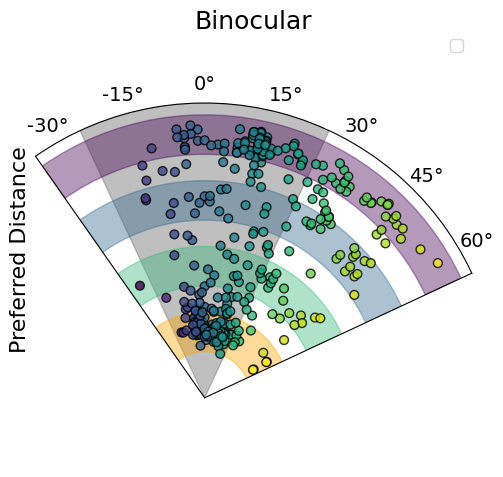

In [65]:
session_reverse.plot_preferred_distance_polar()

In [ ]:
def plot_rf_histogram(self, condition='binocular', bins=20, ax=None, color='steelblue'):
    df = self.reliable_classes['reliable']
    rf_vals = self.extract_condition_feature(df, condition=condition, feature='RF')
    rf_vals = rf_vals[~np.isnan(rf_vals)]

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4))
    else:
        fig = ax.get_figure()

    ax.hist(rf_vals, bins=bins, color=color, edgecolor='black', linewidth=0.5)
    ax.set_xlabel('RF Position (°)', fontsize=16)
    ax.set_ylabel('Number of Cells', fontsize=16)
    ax.tick_params(labelsize=12)
    ax.set_title(self._get_session_title(), fontsize=14, color='grey', pad=2)
    fig.suptitle(f'RF Distribution — {condition.capitalize()}', fontsize=18, fontweight='bold')
    plt.tight_layout()
    return fig

fig = plot_rf_histogram(condition='binocular', bins=20)

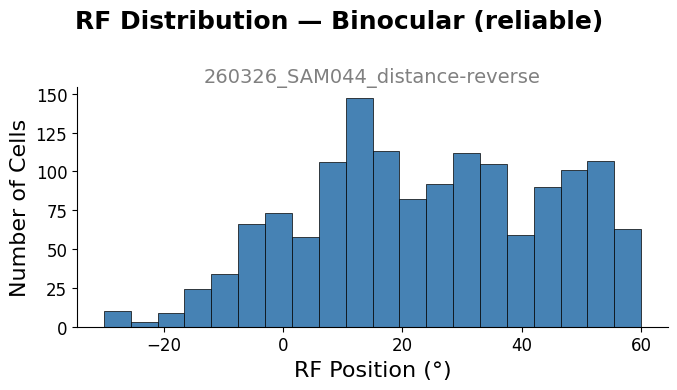

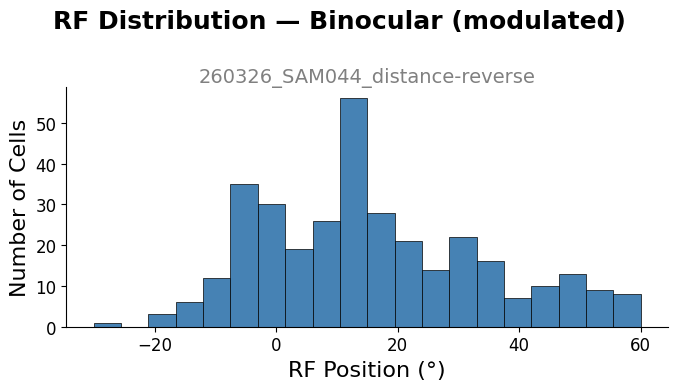

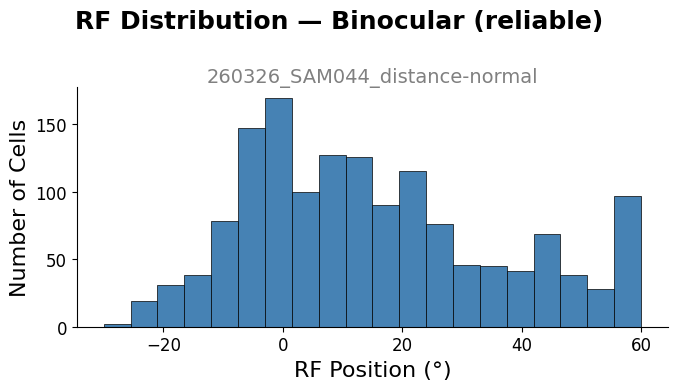

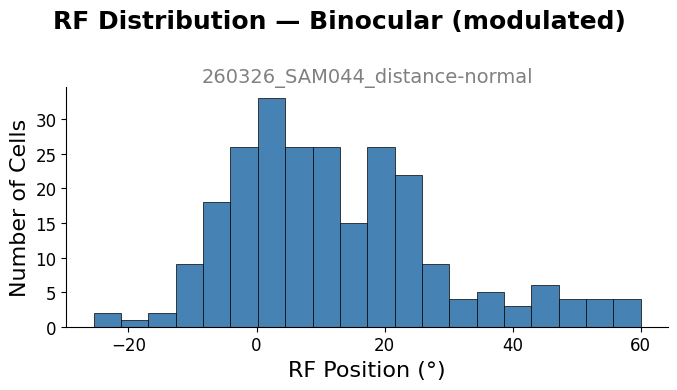

In [72]:
fig = session_reverse.plot_rf_histogram(subset='reliable')
fig = session_reverse.plot_rf_histogram(subset='modulated')
fig = session_normal.plot_rf_histogram(subset='reliable')
fig = session_normal.plot_rf_histogram(subset='modulated')

In [ ]:
normal_bino_ids = set(session_normal.modulated_classes['binocular']['cell_id'].values)
reverse_bino_ids = set(session_reverse.modulated_classes['binocular']['cell_id'].values)

both_ids    = normal_bino_ids & reverse_bino_ids
only_normal = normal_bino_ids - reverse_bino_ids
only_reverse = reverse_bino_ids - normal_bino_ids

print(f"Binocular in both:         {len(both_ids)}")
print(f"Binocular only in normal:  {len(only_normal)}")
print(f"Binocular only in reverse: {len(only_reverse)}")
print(f"Total cells: {len(both_ids) + len(only_normal) + len(only_reverse)}")

Binocular in both:         90
Binocular only in normal:  155
Binocular only in reverse: 246
Total cells: 491


In [ ]:
results_dir = r"D:\data-distance-coding-project\processed-data\260326_SAM044_distance-normal\results"

from src.utils import create_new_result_dir

cell_viz_normal  = CellVisualizer(device_normal)
cell_viz_reverse = CellVisualizer(device_reverse)

dirs = {
    'both':         create_new_result_dir(results_dir, 'both'),
    'only_normal':  create_new_result_dir(results_dir, 'only_normal'),
    'only_reverse': create_new_result_dir(results_dir, 'only_reverse'),
}
groups = {
    'both':         both_ids,
    'only_normal':  only_normal,
    'only_reverse': only_reverse,
}

for group, cell_ids in groups.items():
    print(f'{group}: {len(cell_ids)} cells')
    for cell_id in cell_ids:
        for suffix, viz in [('normal', cell_viz_normal), ('reverse', cell_viz_reverse)]:
            fig = viz.plot_all_traces_colormap_distances(cell_id)
            fig.savefig(os.path.join(dirs[group], f'cell_{cell_id}_{suffix}.png'), bbox_inches='tight', dpi=150)
            plt.close(fig)
        print(f'  cell {cell_id} done')

## Decoding using All Cells

In [43]:
import numpy as np
from src.decoding.Decoders import TrialDecoder, FactoredMLE, AveragedDecoder

# ── helper: build decoder data from a RadialDevice + stats dataframe ─────────
def build_decoder_data(device, session_df):
    """Returns X (n_neurons, n_positions, n_trials), y_dist (n_trials,),
    distances (n_distances,), angle_axis (n_positions,)."""
    # Reliable binocular cells
    def _reliable(row):
        v = row['binocular']
        return isinstance(v, dict) and v.get('reliable', False)
    cell_ids = session_df[session_df.apply(_reliable, axis=1)]['cell_id'].values

    # Binocular trial indices (monocular == 0), exclude control (distance == 4)
    mono_seq = np.array(device.monocular_sequence)
    dist_seq  = np.array(device.distance_sequence)
    trial_mask = (mono_seq == 0) & (dist_seq != 4)
    trial_idx  = np.where(trial_mask)[0]
    y_distance = dist_seq[trial_mask]

    # Build X
    traces = []
    for cell_id in cell_ids:
        cell_idx = np.where(device.suite2p_id == cell_id)[0][0]
        cell_traces = np.stack(
            [device.get_on_trace(cell_idx, int(r)) for r in trial_idx], axis=0
        )  # (n_trials, n_positions)
        traces.append(cell_traces)

    X = np.stack(traces, axis=0)          # (n_neurons, n_trials, n_positions)
    X = X.transpose(0, 2, 1)             # (n_neurons, n_positions, n_trials)

    n_positions = X.shape[1]
    angle_axis = np.linspace(float(device.start_angle), float(device.end_angle), n_positions)
    distances  = np.unique(y_distance)

    return X, y_distance, distances, angle_axis

class _SingleSessionAgg:
    def __init__(self, X, y_distance, distances, angle_axis, df):
        self._X         = X
        self._y         = y_distance
        self._df        = df
        self.distances  = distances
        self.angle_axis = angle_axis
        self.trial_info = {}

    @property
    def n_positions(self):
        return len(self.angle_axis)

    def _get_cell_indices(self, area=None, session=None):
        return list(range(self._X.shape[0]))

    def get_decoder_data(self, monocular=None, area=None, session=None, **kwargs):
        return self._X, self._y

    def get_split_decoder_data(self, monocular=None, area=None, session=None,
                               distances=None, test_fraction=0.5, random_state=None, **kwargs):
        rng   = np.random.RandomState(random_state)
        X, y  = self._X, self._y
        dists = self.distances if distances is None else np.array(distances)

        train_avgs, test_avgs = [], []
        for d in dists:
            idx = np.where(y == d)[0]
            rng.shuffle(idx)
            split = max(1, int(len(idx) * (1 - test_fraction)))
            train_avgs.append(X[:, :, idx[:split]].mean(axis=2))
            test_avgs.append( X[:, :, idx[split:]].mean(axis=2))

        return np.stack(train_avgs, axis=2), np.stack(test_avgs, axis=2), dists



# ── run ──────────────────────────────────────────────────────────────────────
X_n, y_n, dist_n, ang_n = build_decoder_data(device_normal,  df_normal)
X_r, y_r, dist_r, ang_r = build_decoder_data(device_reverse, df_reverse)

agg_normal  = _SingleSessionAgg(X_n, y_n, dist_n, ang_n, df_normal)
agg_reverse = _SingleSessionAgg(X_r, y_r, dist_r, ang_r, df_reverse)

print(f"Normal:  {X_n.shape[0]} cells, {X_n.shape[2]} trials")
print(f"Reverse: {X_r.shape[0]} cells, {X_r.shape[2]} trials")

C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_76668\409230445.py:34: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  angle_axis = np.linspace(float(device.start_angle), float(device.end_angle), n_positions)


Normal:  2212 cells, 80 trials
Reverse: 2180 cells, 80 trials


In [ ]:
def align_results(*results):
    n_pos = min(res['angle_axis'].shape[0] for res in results)
    aligned = []
    for res in results:
        a = {**res, 'angle_axis': res['angle_axis'][:n_pos]}
        for key in ('pred_dist', 'pred_angle'):
            if key in res:
                a[key] = res[key][..., :n_pos]
        for key in ('true_dist', 'true_angle'):
            if key in res and res[key].ndim > 1:  # only truncate if has positions axis (AveragedDecoder)
                a[key] = res[key][..., :n_pos]
        for key in ('angle_mae_by_pos', 'dist_acc_by_pos'):
            if key in res:
                a[key] = res[key][:n_pos]
        aligned.append(a)
    return aligned

In [63]:
TrialDec = TrialDecoder()

trial_normal = TrialDec.cross_validate(agg_normal, monocular=0, loo=True)
trial_reverse = TrialDec.cross_validate(agg_reverse, monocular=0, loo=True)

trial_normal, trial_reverse = align_results(trial_normal, trial_reverse)

Trial 80/80
  Angle MAE:    7.02°
  Dist Acc:     31.7%
Trial 80/80
  Angle MAE:    5.51°
  Dist Acc:     41.5%


C:\Users\acostamendoza\projects\distance-project\radial-analysis\src\decoding\Decoders.py:883: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


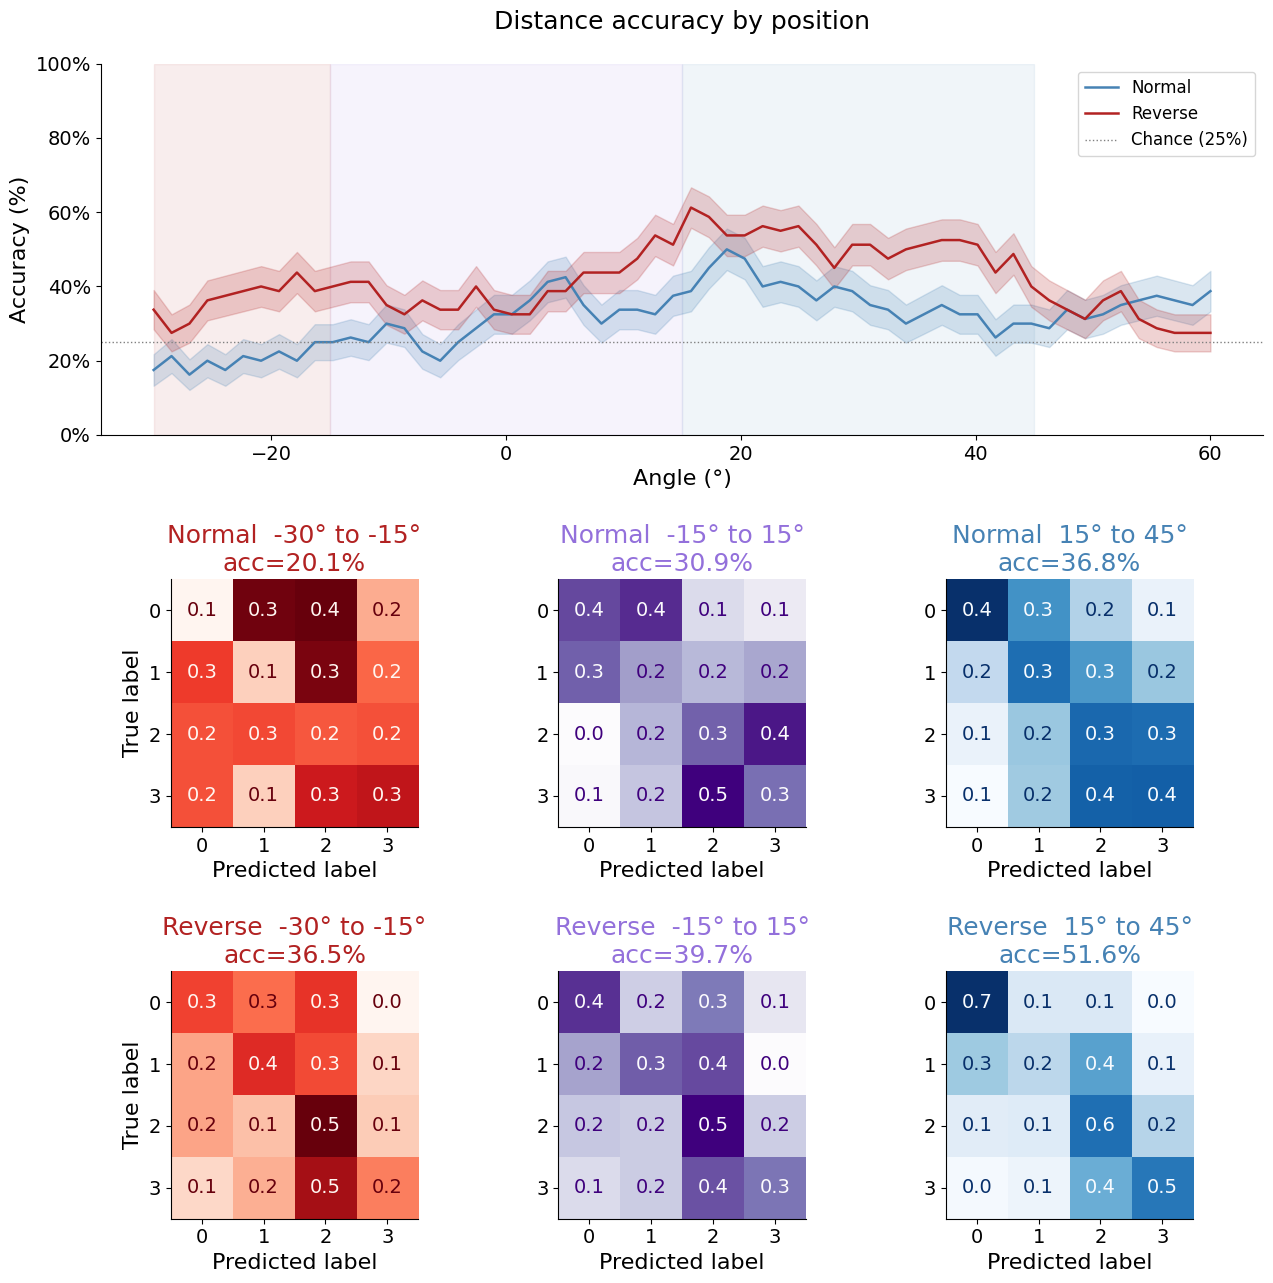

In [64]:
fig = TrialDec.plot_distance_results(trial_normal, trial_reverse, labels=['Normal', 'Reverse'])

In [45]:
AvgDec = AveragedDecoder()

averaged_normal = AvgDec.cross_validate(agg_normal, monocular=0, n_repeats = 20)
averaged_reverse = AvgDec.cross_validate(agg_reverse, monocular=0, n_repeats = 20)

Repeat 20/20
  Angle MAE:    1.50°
  Dist Acc:     37.1%
Repeat 20/20
  Angle MAE:    1.79°
  Dist Acc:     47.1%


C:\Users\acostamendoza\projects\distance-project\radial-analysis\src\decoding\Decoders.py:1299: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  


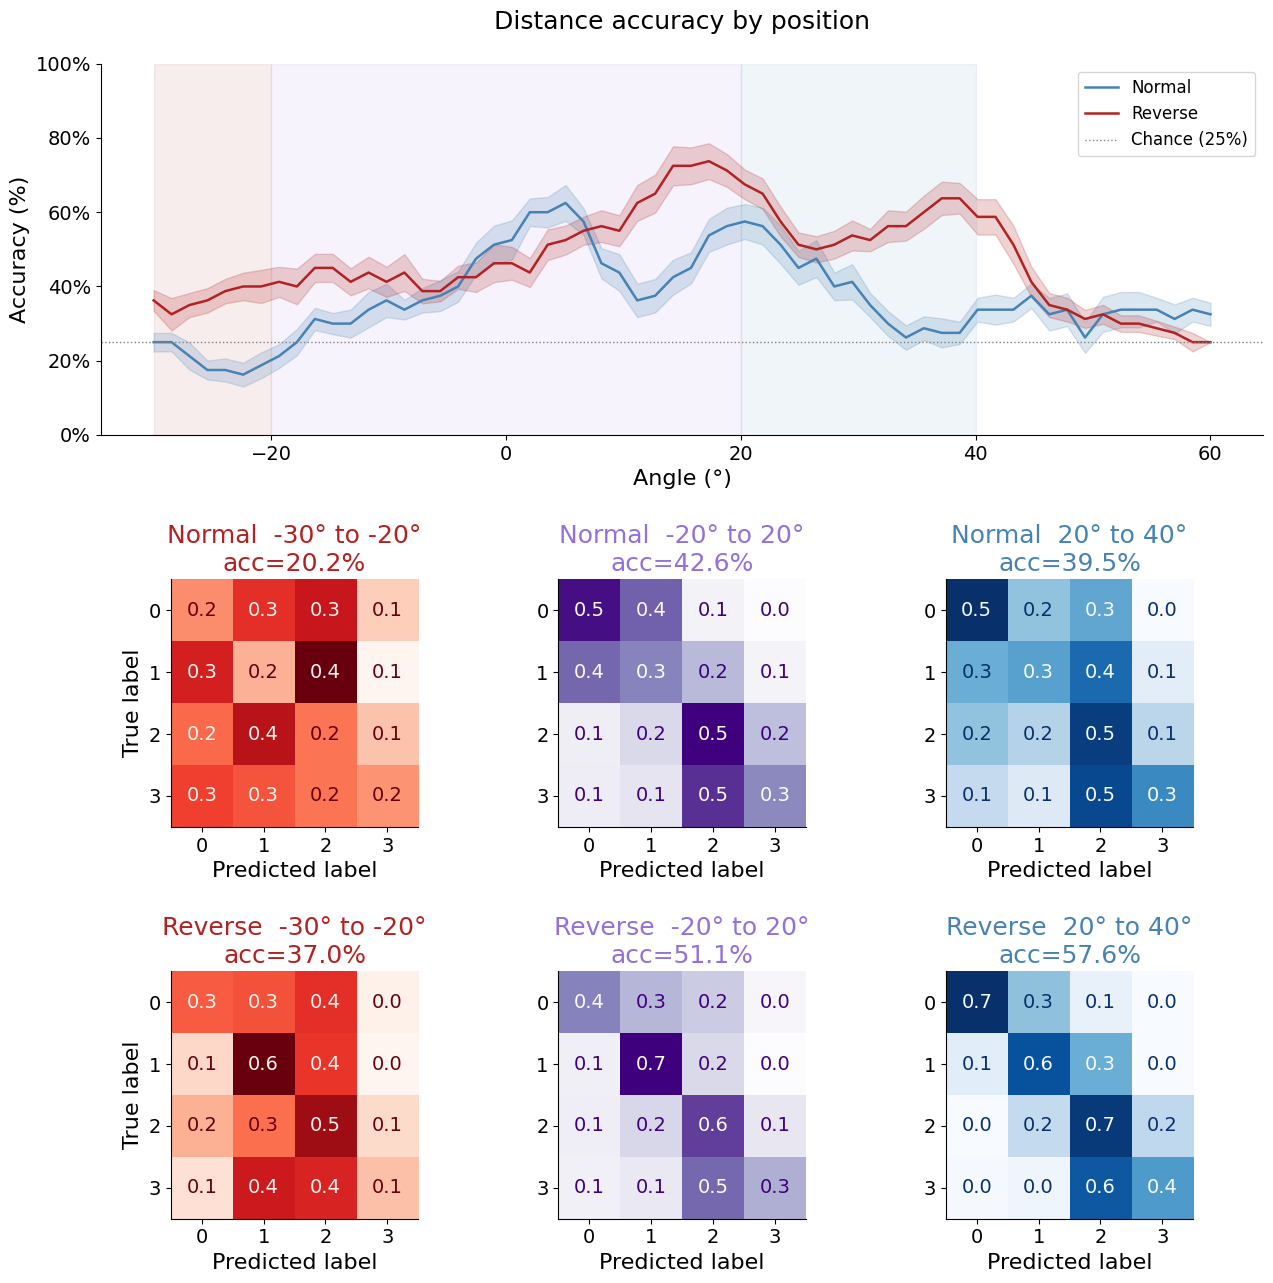

In [ ]:



trial_normal, trial_reverse = align_results(trial_normal, trial_reverse)
averaged_normal, averaged_reverse = align_results(averaged_normal, averaged_reverse)

fig = AvgDec.plot_distance_results(averaged_normal, averaged_reverse, labels=['Normal', 'Reverse'])


In [ ]:
# Decoding using top cells

In [58]:
# --- cell indices shared by decoder ---

def get_top_dti_cells(agg, k_cells):
    _cell_idx_list = agg._get_cell_indices(area=None)

    # DTI ranking
    bino_dti      = agg._df.loc[_cell_idx_list, 'binocular'].apply(lambda d: d['DTI']).values
    rank_dti_desc = np.argsort(bino_dti)[::-1]

    cell_idx = rank_dti_desc[:k_cells]

    return cell_idx

def get_top_corr_cells(agg, k_cells):

    _cell_idx_list = agg._get_cell_indices(area=None)

    # DTI ranking
    bino_dti      = agg._df.loc[_cell_idx_list, 'binocular'].apply(lambda d: d['reliable_corr']).values
    rank_corr_desc = np.argsort(bino_dti)[::-1]

    cell_idx = rank_corr_desc[:k_cells]

    return cell_idx

top_normal_cells = get_top_corr_cells(agg_normal, 100)
top_reverse_cells = get_top_corr_cells(agg_reverse, 100)

In [57]:
print(df_normal['binocular'][0].keys())

dict_keys(['RF', 'reliable', 'reliable_corr', 'bootstrap_pvalue', 'anova_pvalue', 'consistency', 'DTI', 'distance'])


Repeat 10/10
  Angle MAE:    2.03°
  Dist Acc:     36.9%
Repeat 10/10
  Angle MAE:    1.93°
  Dist Acc:     42.5%


C:\Users\acostamendoza\projects\distance-project\radial-analysis\src\decoding\Decoders.py:1299: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  


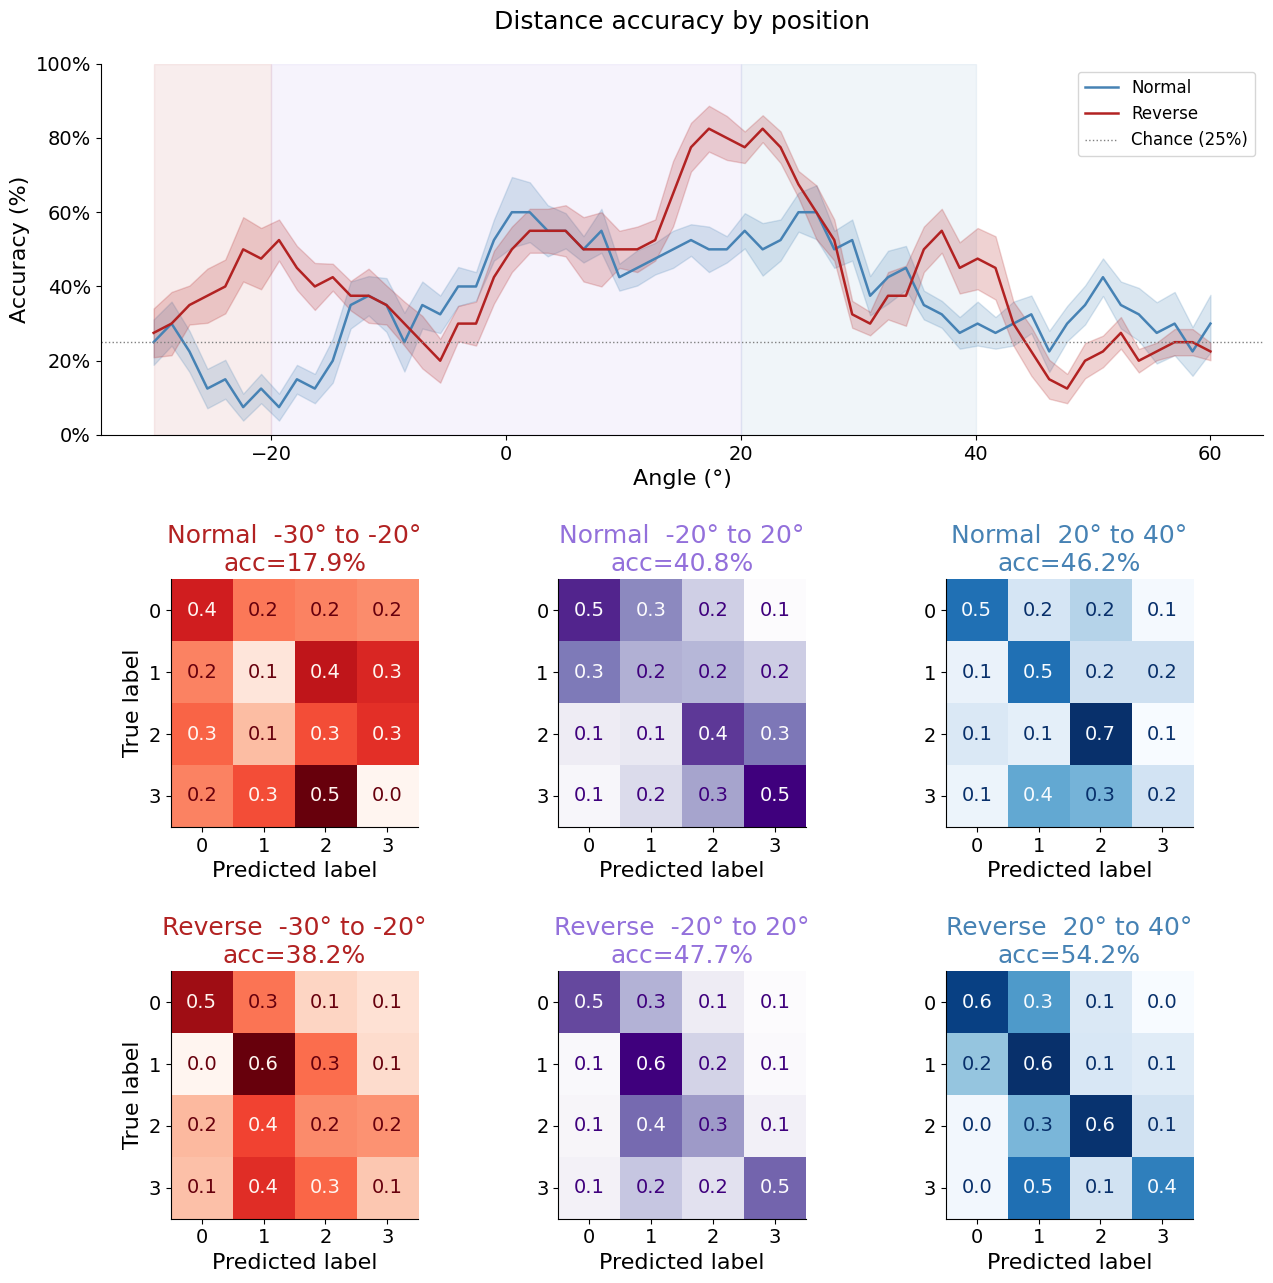

In [60]:
top_normal_cells = get_top_corr_cells(agg_normal, 100)
top_reverse_cells = get_top_corr_cells(agg_reverse, 100)

averaged_normal = AvgDec.cross_validate(agg_normal, monocular=0, cell_idx = top_normal_cells)
averaged_reverse = AvgDec.cross_validate(agg_reverse, monocular=0, cell_idx = top_reverse_cells)

averaged_normal, averaged_reverse = align_results(averaged_normal, averaged_reverse)
fig = AvgDec.plot_distance_results(averaged_normal, averaged_reverse, labels=['Normal', 'Reverse'])

ValueError: x and y must have same first dimension, but have shapes (4,) and (60,)

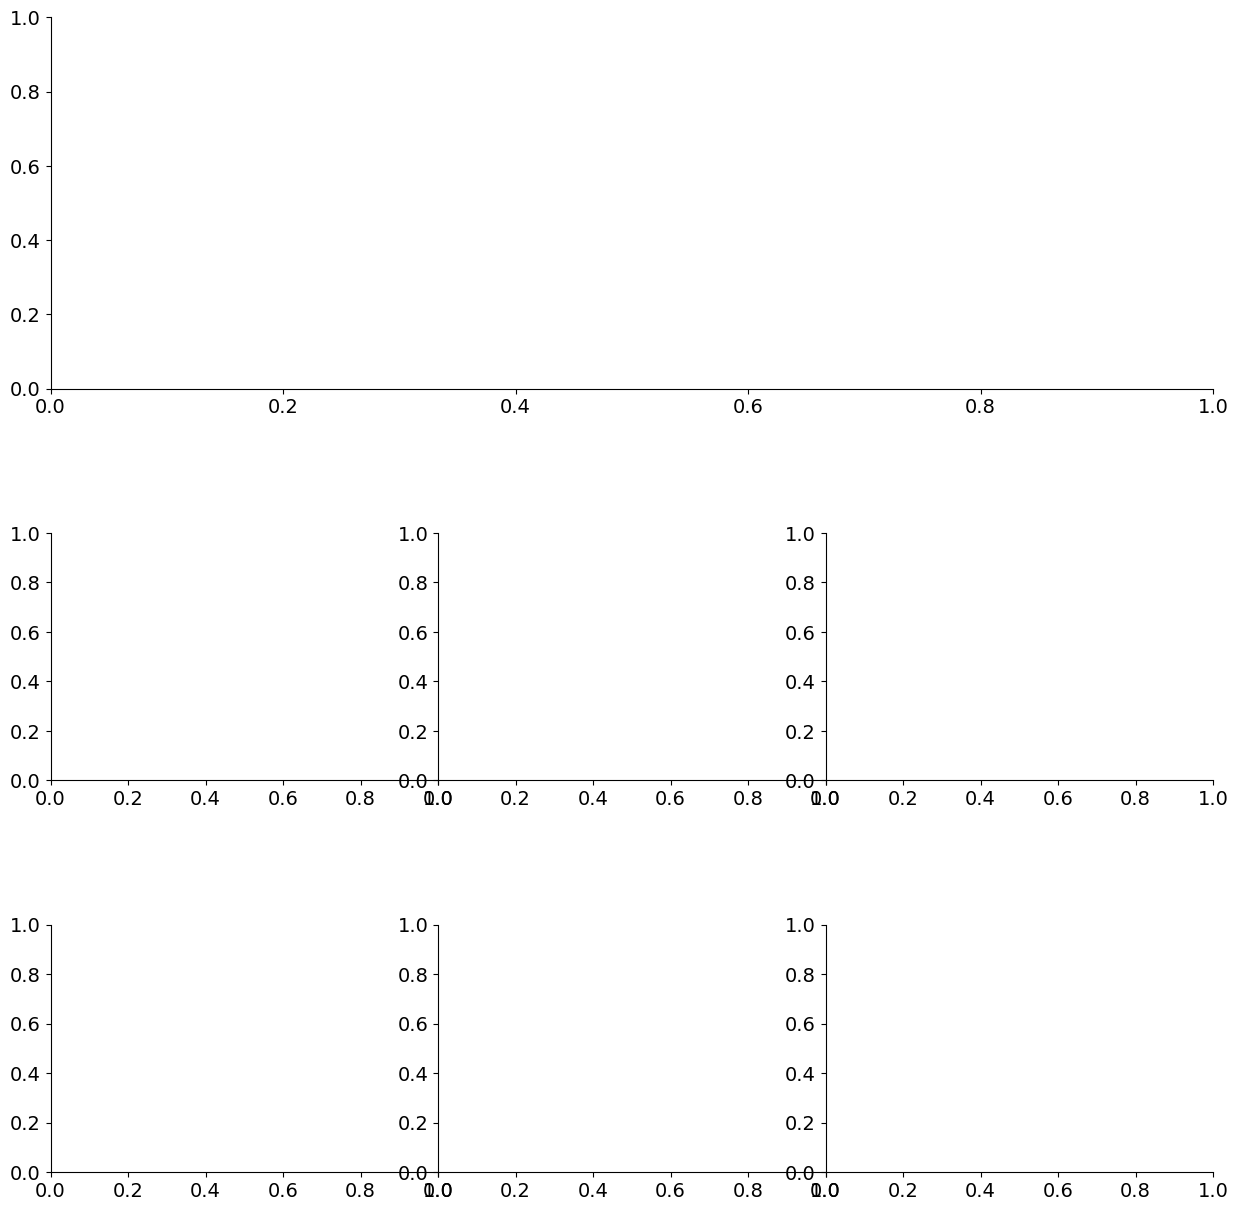

In [96]:
def align_results(*results):
    """Truncate all results to the minimum number of angle positions."""
    n_pos = min(res['pred_dist'].shape[1] for res in results)
    aligned = []
    for res in results:
        aligned.append({**res,
            'pred_dist':  res['pred_dist'][:, :n_pos],
            'pred_angle': res['pred_angle'][:, :n_pos],
            'true_angle': res['true_angle'][:, :n_pos],
            'angle_axis': res['angle_axis'][:n_pos],
            'angle_mae_by_pos': res['angle_mae_by_pos'][:n_pos],
            'dist_acc_by_pos':  res['dist_acc_by_pos'][:n_pos],
        })
    return aligned

normal_a, reverse_a = align_results(results_normal, results_reverse)
AvgDecoder.plot_distance_results(normal_a, reverse_a)

ValueError: x and y must have same first dimension, but have shapes (60,) and (61,)

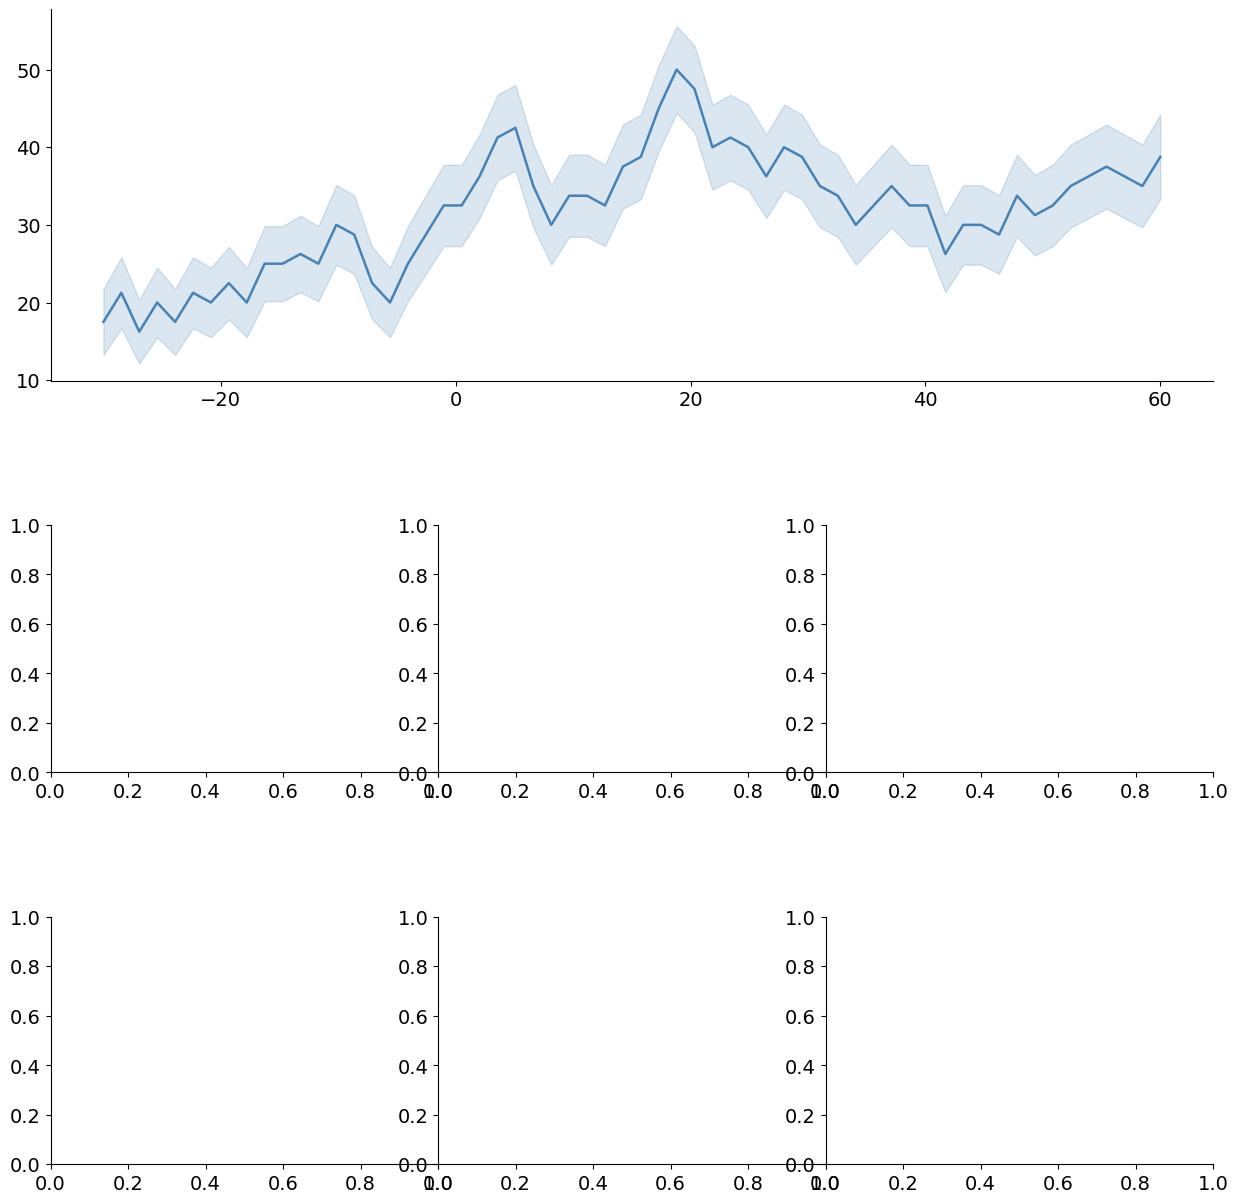

In [79]:
Decoder.plot_distance_results(normal, reverse)

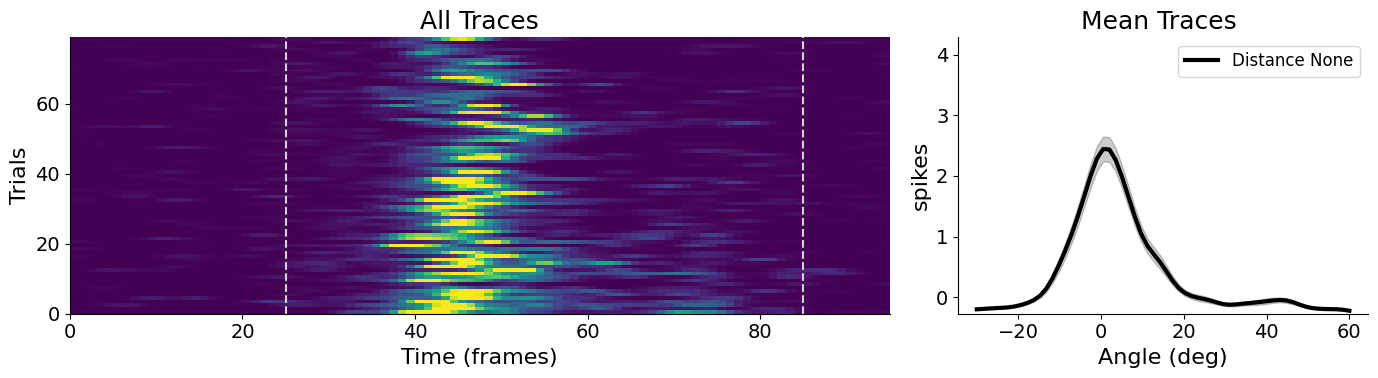

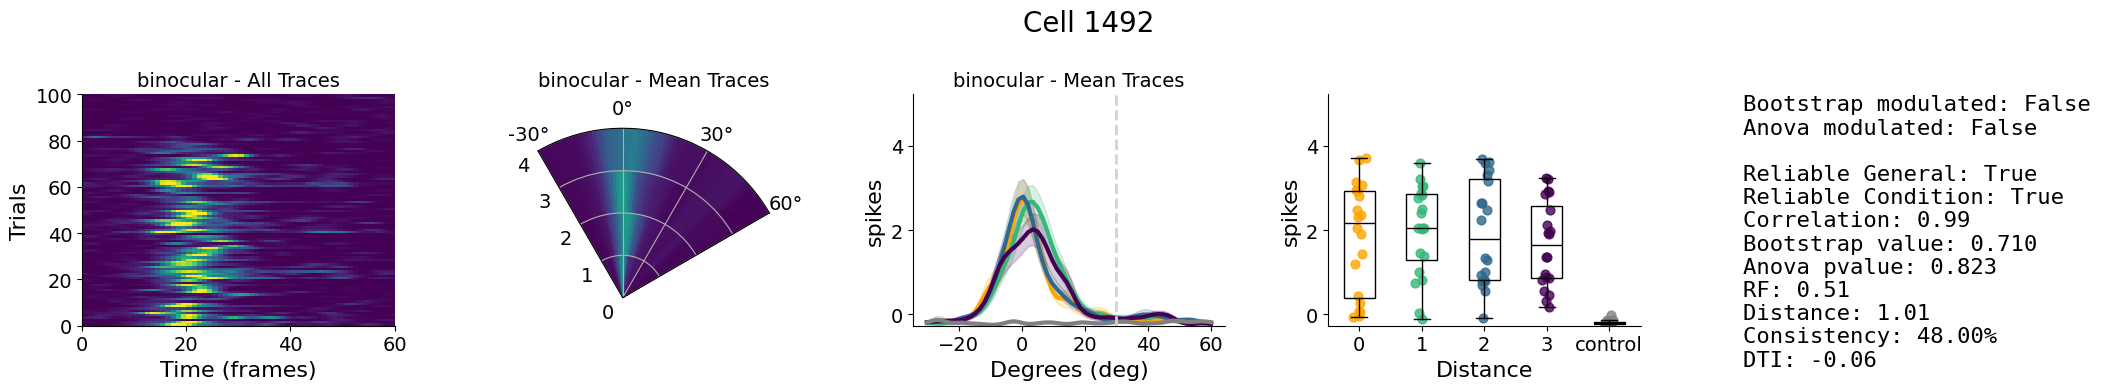

In [18]:
cell = 1492
fig = visualizer.plot_all_traces_colormap(cell=cell)
fig = visualizer.plot_all_traces_colormap_distances(cell = cell)

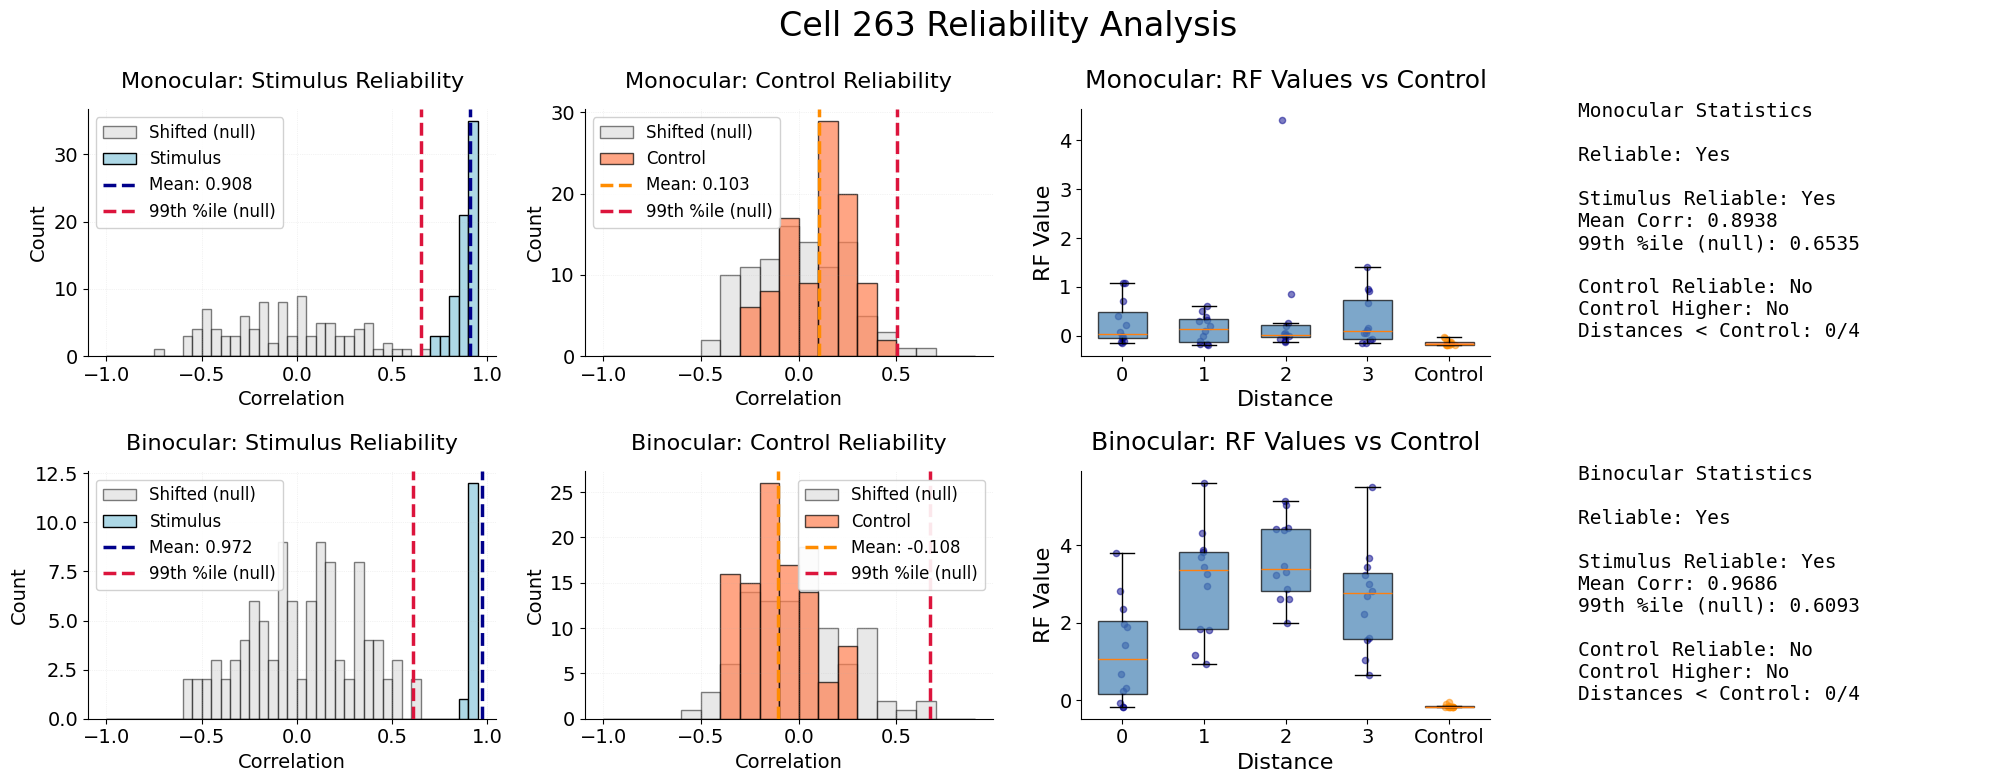

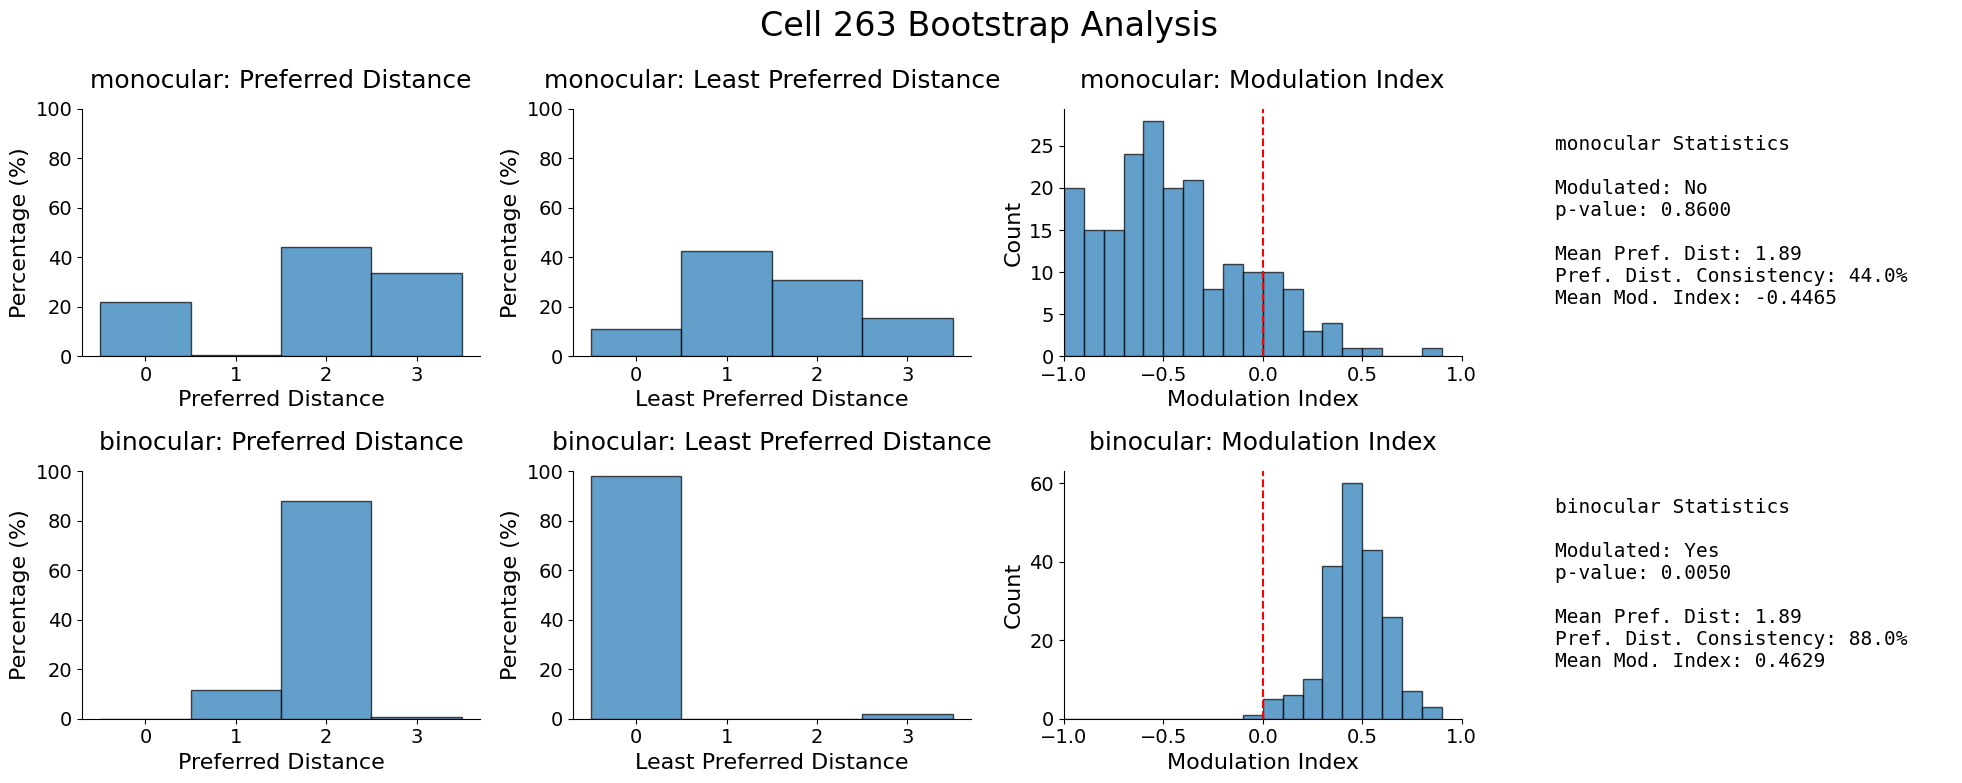

In [4]:
cell = 263
fig = visualizer.plot_reliability_analysis(cell = cell)
fig = visualizer.plot_bootstrap_modulation(cell = cell)